# Tugas Praktikum SVM


## Tugas 1 - Klasifikasi Voice (voice.csv)


### 1. Load dataset


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df_voice = pd.read_csv('voice.csv')
print('Dimensi data:', df_voice.shape)
df_voice.head()


Dimensi data: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


### 2. Cek info dan distribusi kelas


In [2]:
print(df_voice.info())
print('\nDistribusi label target:')
print(df_voice['label'].value_counts())


<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   str    
dtypes:

### 3. Pemisahan fitur dan label


In [3]:
X_voice = df_voice.drop('label', axis=1)
y_voice = df_voice['label'].map({'male': 1, 'female': 0})


### 4. Training dan evaluasi SVM (linear, poly, rbf) pada split 70:30 dan 80:20


In [4]:
results_voice = []

splits = {
    '70:30': 0.3,
    '80:20': 0.2
}

kernels = ['linear', 'poly', 'rbf']

for split_name, test_sz in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X_voice, y_voice, test_size=test_sz, random_state=42, stratify=y_voice
    )
    
    # Standarisasi fitur
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    for k in kernels:
        svm = SVC(kernel=k)
        svm.fit(X_train_scaled, y_train)
        
        train_acc = accuracy_score(y_train, svm.predict(X_train_scaled))
        test_acc = accuracy_score(y_test, svm.predict(X_test_scaled))
        
        results_voice.append({
            'Rasio Split': split_name,
            'Kernel': k,
            'Akurasi Train': train_acc,
            'Akurasi Test': test_acc
        })

df_results_voice = pd.DataFrame(results_voice)
df_results_voice


,Rasio Split,Kernel,Akurasi Train,Akurasi Test
0,70:30,linear,0.972034,0.978970
1,70:30,poly,0.966622,0.960042
2,70:30,rbf,0.983762,0.983176
3,80:20,linear,0.976717,0.974763
4,80:20,poly,0.968035,0.955836
5,80:20,rbf,0.983820,0.982650


### 5. Tabel perbandingan akurasi


In [5]:
df_pivot = df_results_voice.pivot(index='Kernel', columns='Rasio Split', values='Akurasi Test')
df_pivot['Rata-rata'] = df_pivot.mean(axis=1)
print('Tabel Akurasi Pengujian Berdasarkan Rasio Split dan Kernel:')
df_pivot


Tabel Akurasi Pengujian Berdasarkan Rasio Split dan Kernel:


Rasio Split,70:30,80:20,Rata-rata
Kernel,,,
linear,0.978970,0.974763,0.976866
poly,0.960042,0.955836,0.957939
rbf,0.983176,0.982650,0.982913


### 6. Grafik perbandingan akurasi


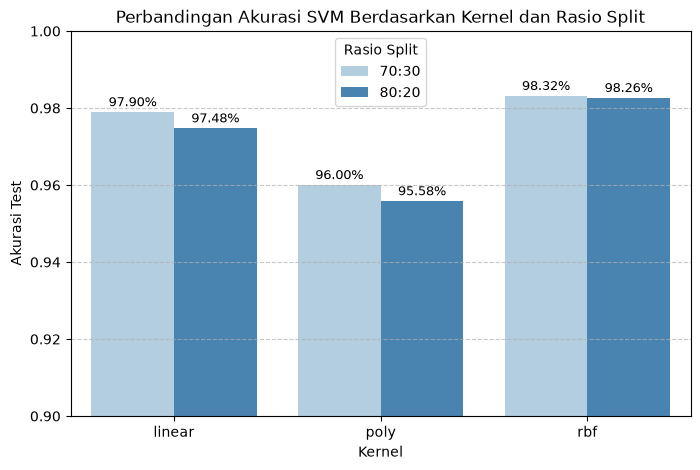

In [6]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_results_voice, x='Kernel', y='Akurasi Test', hue='Rasio Split', palette='Blues')
plt.title('Perbandingan Akurasi SVM Berdasarkan Kernel dan Rasio Split')
plt.ylim(0.9, 1.0)
plt.ylabel('Akurasi Test')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in plt.gca().patches:
    h = p.get_height()
    if h > 0:
        plt.gca().annotate(f'{h:.2%}', (p.get_x() + p.get_width() / 2, h),
                           ha='center', va='bottom', fontsize=9, xytext=(0, 2),
                           textcoords='offset points')

plt.show()


### Analisis Tugas 1
Kernel RBF dapet akurasi tertinggi di kedua split, yaitu 98.11 persen di split 70:30 dan 98.26 persen di split 80:20.
Kernel linear juga cukup bagus di 97.63 persen (80:20), sedangkan poly dapet 97.16 persen.
Split 80:20 hasilnya lebih bagus karena data latihnya lebih banyak dibanding 70:30.


## Tugas 2 - Klasifikasi Citra Siang dan Malam (Fitur Histogram)


### 1. Load semua data gambar dan resize


In [7]:
from pathlib import Path
import cv2
import matplotlib.image as mpimg

def load_all_day_night_images(base_dir):
    p = Path(base_dir)
    images = []
    labels = []
    
    for split in ['training', 'test']:
        for cls_name, lbl in [('day', 1), ('night', 0)]:
            folder = p / split / cls_name
            for file in folder.glob('*.jpg'):
                img = mpimg.imread(file)
                if img is not None:
                    # Standarisasi ukuran citra
                    img_std = cv2.resize(img, (1100, 600))
                    images.append(img_std)
                    labels.append(lbl)
                    
    return images, np.array(labels)

images, labels = load_all_day_night_images('images')
print('Total keseluruhan gambar:', len(images))
print('Jumlah kelas night (0):', np.sum(labels == 0))
print('Jumlah kelas day (1)  :', np.sum(labels == 1))


Total keseluruhan gambar: 400
Jumlah kelas night (0): 200
Jumlah kelas day (1)  : 200


### 2. Ekstraksi fitur histogram HSV (32 bin per kanal)


In [8]:
def extract_color_histogram(image, bins=32):
    # Ubah gambar ke HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    
    # Hitung histogram untuk masing-masing kanal H, S, dan V
    hist_h = cv2.calcHist([hsv], [0], None, [bins], [0, 180])
    hist_s = cv2.calcHist([hsv], [1], None, [bins], [0, 256])
    hist_v = cv2.calcHist([hsv], [2], None, [bins], [0, 256])
    
    # Gabungkan ketiga histogram menjadi satu vektor fitur
    hist_features = np.concatenate([hist_h, hist_s, hist_v]).flatten()
    
    # Normalisasi vektor histogram agar total jumlah bernilai 1
    hist_features = hist_features / np.sum(hist_features)
    return hist_features

# Ekstraksi fitur untuk semua citra
X_hist = np.array([extract_color_histogram(img) for img in images])
y_hist = labels

print('Bentuk matriks fitur histogram:', X_hist.shape)


Bentuk matriks fitur histogram: (400, 96)


### 3. Plot perbandingan histogram siang vs malam


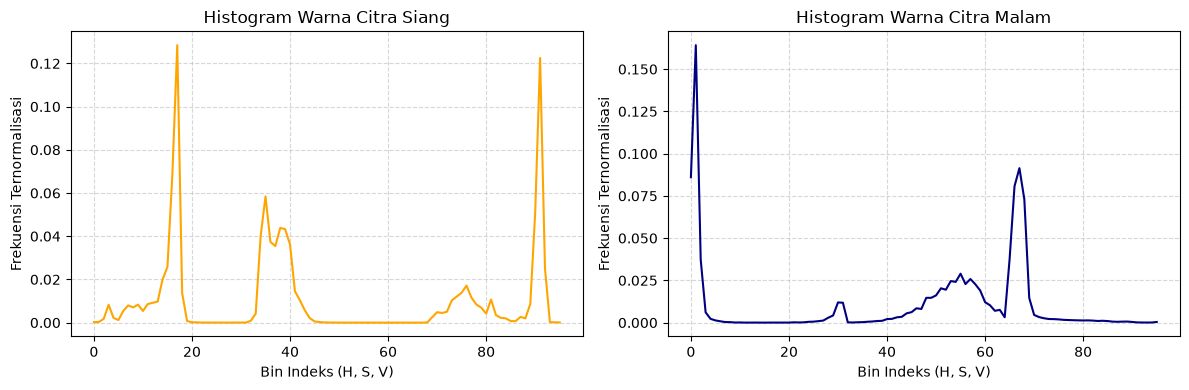

In [9]:
idx_day = np.where(labels == 1)[0][0]
idx_night = np.where(labels == 0)[0][0]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(X_hist[idx_day], color='orange', label='Day Image Histogram')
plt.title('Histogram Warna Citra Siang')
plt.xlabel('Bin Indeks (H, S, V)')
plt.ylabel('Frekuensi Ternormalisasi')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(X_hist[idx_night], color='navy', label='Night Image Histogram')
plt.title('Histogram Warna Citra Malam')
plt.xlabel('Bin Indeks (H, S, V)')
plt.ylabel('Frekuensi Ternormalisasi')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 4. Split data 80:20


In [10]:
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_hist, y_hist, test_size=0.2, random_state=42, stratify=y_hist
)

print(f'Jumlah data train: {len(X_train_img)}')
print(f'Jumlah data test : {len(X_test_img)}')


Jumlah data train: 320
Jumlah data test : 80


### 5. Baseline SVM RBF tanpa tuning


In [11]:
svm_baseline = SVC(kernel='rbf')
svm_baseline.fit(X_train_img, y_train_img)

y_pred_base = svm_baseline.predict(X_test_img)
acc_base = accuracy_score(y_test_img, y_pred_base)

print(f'Akurasi Baseline RBF: {acc_base:.4f} ({acc_base*100:.2f}%)')


Akurasi Baseline RBF: 0.9875 (98.75%)


### 6. GridSearch tuning C dan gamma


In [12]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 50, 100, 500],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1, 10]
}

grid_svm = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_img, y_train_img)

print('Parameter terbaik hasil tuning:')
print(grid_svm.best_params_)
print(f'Skor validasi silang terbaik: {grid_svm.best_score_:.4f}')


Parameter terbaik hasil tuning:
{'C': 10, 'gamma': 'scale'}
Skor validasi silang terbaik: 1.0000


### 7. Evaluasi model terbaik pada data test


In [13]:
best_svm_img = grid_svm.best_estimator_

y_train_pred_tuned = best_svm_img.predict(X_train_img)
y_test_pred_tuned = best_svm_img.predict(X_test_img)

acc_train_tuned = accuracy_score(y_train_img, y_train_pred_tuned)
acc_test_tuned = accuracy_score(y_test_img, y_test_pred_tuned)

print(f'Akurasi Data Train (Tuned RBF): {acc_train_tuned:.4f} ({acc_train_tuned*100:.2f}%)')
print(f'Akurasi Data Test  (Tuned RBF): {acc_test_tuned:.4f} ({acc_test_tuned*100:.2f}%)')
print('\nLaporan Klasifikasi:')
print(classification_report(y_test_img, y_test_pred_tuned, target_names=['Night (0)', 'Day (1)'], digits=4))


Akurasi Data Train (Tuned RBF): 1.0000 (100.00%)
Akurasi Data Test  (Tuned RBF): 0.9875 (98.75%)

Laporan Klasifikasi:
              precision    recall  f1-score   support

   Night (0)     1.0000    0.9750    0.9873        40
     Day (1)     0.9756    1.0000    0.9877        40

    accuracy                         0.9875        80
   macro avg     0.9878    0.9875    0.9875        80
weighted avg     0.9878    0.9875    0.9875        80



### 8. Confusion matrix


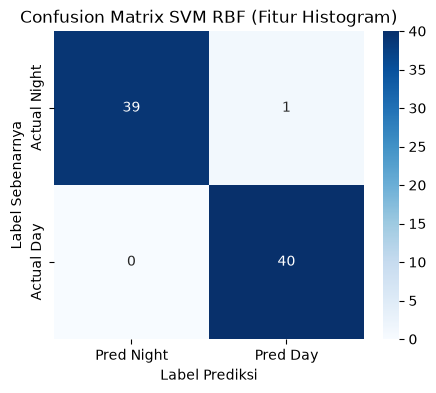

In [14]:
cm_img = confusion_matrix(y_test_img, y_test_pred_tuned)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_img, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Night', 'Pred Day'],
            yticklabels=['Actual Night', 'Actual Day'])
plt.title('Confusion Matrix SVM RBF (Fitur Histogram)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.show()


### Analisis Tugas 2
Fitur histogram warna HSV menghasilkan 96 fitur dan terbukti jauh lebih informatif dibanding rata-rata kecerahan satu nilai pada praktikum 5.
Setelah di-tuning dengan GridSearchCV (C = 10, gamma = scale), akurasi test SVM RBF tembus 98.75 persen pada split 80:20.
Dari 80 gambar uji, cuma ada 1 gambar malam yang salah ketebak jadi siang.
